# Longest summer dry spell vs. land warming, 30–60°N: CMIP6 models (2021–2049)

Same figure as `cesm2_ens_land_dry_consect_temp_histo_fut.ipynb`, with CESM2 replaced by the CMIP6 models, using the first member of each model (`MEMBERS_PER_MODEL = 1`; lowest r, then i, p, f, the same member as in the other CMIP6 notebooks).

- **Lines:** one KDE line per model per year (2021–2049), so every model has the same number of lines. Each line is the distribution over the land cells of the model's member in that year, with cos(lat) weights (with `MEMBERS_PER_MODEL` > 1, the members of a year are pooled, as the CESM2 original did). It is coloured by the model's temperature change over land at 30–60°N relative to 2021.
- **Data:** the ssp370 ensemble files in `30-60N/ensemble` (NCO or Python version) and annual `tas` from cmip6-ng. Land is `sftlf > 0`, with cos(lat) area weights. BCC-CSM2-MR has no sftlf file and uses the `FALLBACK_MASK_MODEL` mask.
- **KDE:** weighted Gaussian KDE with Scott's bandwidth, as in `sns.kdeplot(weights=..., bw_adjust=1)`. It's computed directly, because seaborn is far too slow for pooled samples of up to ~50 members. Dry-spell lengths are whole days, so the weights are summed per length, and the bandwidth is set to what the full sample would get, so the curves match seaborn's.
- **Regression (per model):** x is the raw annual land-mean temperature (30–60°N) of the model's member, as in the CESM2 and IFS notebooks. y is the area-weighted land-mean longest dry spell, one point per year. Year-to-year temperature variability in x lowers the slope compared with a trend-smoothed x (regression dilution). The table gives slope (days/°C), R² and p-value per model, and the CMIP6 mean is the average of the model values.

In [43]:
import os
import re
from collections import defaultdict

import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')

In [44]:
# ── settings ─────────────────────────────────────────────────────────────────
ENS_DIR       = '/home/jwille/xenon_data/NextGEMS/dry_spells/CMIP6/30-60N/ensemble'   # dry_spell_<model>_ssp370_ensemble_native.nc
TAS_DIR       = '/net/atmos/data/cmip6-ng/tas/ann/native'
SFTLF_DIR     = '/net/atmos/data/cmip6-ng/sftlf/fx/native'
EXPERIMENT    = 'ssp370'
YEARS         = (2021, 2049)
REF_YEAR      = 2021
latitude      = [30, 60]

FALLBACK_MASK_MODEL = 'MPI-ESM1-2-HR'   # mask used for models without an sftlf file (BCC-CSM2-MR)
EXCLUDE_MODELS      = []                # e.g. ['BCC-CSM2-MR']
MEMBERS_PER_MODEL   = 1                 # first N members of each model (sorted r, i, p, f); None = all members

CBAR_RANGE       = (-0.1, 2.4)          # colour-bar limits (°C); None = 1st-99th percentile of the data
LINE_WIDTH       = 1.5                  # combined figure, one line per model and year (CESM2 original: 2.0)
PANEL_LINE_WIDTH = 1.0                  # per-model panels, one line per member and year

# KDE evaluation grid and plot range (as in the original)
xmin, xmax = 0, 185
bin_width  = 2
X_GRID     = np.linspace(xmin, xmax, 371)

OUT_FIG   = '/home/jwille/images/global_paper/mid_lat_land_cmip6_ens_histo_dry_spell_temp_1mem.pdf'
OUT_TABLE = '/home/jwille/images/global_paper/mid_lat_land_cmip6_dry_spell_temp_regression.csv'
OUT_FIG_PANELS = '/home/jwille/images/global_paper/mid_lat_land_cmip6_ens_histo_dry_spell_temp_per_model_1mem.pdf'
PANEL_COLS     = 5                      # panels per row in the per-model figure

In [45]:
FNAME = re.compile(r'^(?P<prefix>dry_spell|tas_ann)_(?P<model>[^_]+)_(?P<exp>[^_]+)_(?P<member>r\d+i\d+p\d+f\d+)_[^_]+\.nc$')


def member_sort_key(member):
    return [int(n) for n in re.findall(r'\d+', member)]


def nearest_regrid(src, lat, lon):
    """Nearest-neighbour match of a lat/lon field to the given lat/lon (lon periodic).
    Identical grids give exactly the original values."""
    ilat = np.abs(src.lat.values[:, None] - np.asarray(lat)[None, :]).argmin(axis=0)
    dlon = (src.lon.values[:, None] - np.asarray(lon)[None, :] + 180) % 360 - 180
    ilon = np.abs(dlon).argmin(axis=0)
    return xr.DataArray(src.values[np.ix_(ilat, ilon)], dims=('lat', 'lon'), coords={'lat': lat, 'lon': lon})


def find_sftlf(model):
    """sftlf file of a model: historical preferred, else any experiment; None if there is none."""
    pat = re.compile(rf'^sftlf_fx_{re.escape(model)}_(?P<exp>[^_]+)_(?P<mem>[^_]+)_[^_]+\.nc$')
    cands = [(m['exp'] != 'historical', member_sort_key(m['mem']), f)
             for f in os.listdir(SFTLF_DIR) if (m := pat.match(f))]
    return os.path.join(SFTLF_DIR, sorted(cands)[0][2]) if cands else None


def land_mask(model, lat, lon):
    path = find_sftlf(model)
    src = xr.open_dataset(path or find_sftlf(FALLBACK_MASK_MODEL))['sftlf'].load()
    return (nearest_regrid(src, lat, lon) > 0).values, (os.path.basename(path) if path else f'{FALLBACK_MASK_MODEL} (fallback)')


def kde_curve(values, weights, x_grid):
    """Weighted Gaussian KDE with Scott's bandwidth, identical to sns.kdeplot(x=values, weights=weights,
    bw_adjust=1) (density). Values are aggregated to distinct lengths with summed weights; the bandwidth
    and weighted covariance are those of the full sample."""
    w = weights / weights.sum()
    u, inv = np.unique(values, return_inverse=True)
    agg = np.bincount(inv, weights=w)
    sw2 = np.sum(w ** 2)
    if u.size < 2:
        return np.zeros_like(x_grid)
    bw = sw2 ** (1 / 5) * np.sqrt((1 - np.sum(agg ** 2)) / (1 - sw2))
    return stats.gaussian_kde(u, weights=agg, bw_method=bw)(x_grid)

In [46]:
# ── ensemble files (member, year, lat, lon) + the tas file of each member ──
ENS = re.compile(r'^dry_spell_(?P<model>[^_]+)_(?P<exp>[^_]+)_ensemble_[^_]+\.nc$')
ens_files = sorted(((m['model'], f) for f in os.listdir(ENS_DIR)
                    if (m := ENS.match(f)) and m['exp'] == EXPERIMENT and m['model'] not in EXCLUDE_MODELS),
                   key=lambda mf: mf[0].lower())
tas_files = {(m['model'], m['member']): f for f in os.listdir(TAS_DIR)
             if (m := FNAME.match(f)) and m['prefix'] == 'tas_ann' and m['exp'] == EXPERIMENT}


def member_labels(ds):
    """Member names of an ensemble file: 'member_labels' attribute (NCO version, member = 1..N)
    or the member coordinate itself (Python version, member = 'r1i1p1f1', ...)."""
    lab = ds['member'].attrs.get('member_labels') or ds.attrs.get('member_labels')
    return lab.split(',') if lab else [str(m) for m in ds['member'].values]


lines = []          # one dict per model and year: curve, dT (combined figure, all members pooled)
member_lines = []   # one dict per model, member and year: curve, dT (per-model panels)
per_model = {}      # model -> land-mean dry spell and land-mean temperature, DataFrames (year x member)

for model, fname in ens_files:
    ens = xr.open_dataset(os.path.join(ENS_DIR, fname))
    labels = member_labels(ens)
    da = ens['dry_spell'].sel(year=slice(*YEARS)).load()
    if len(labels) != da.sizes['member']:
        raise ValueError(f'{model}: {len(labels)} member labels but {da.sizes["member"]} members in {fname}')
    order = sorted(range(len(labels)), key=lambda i: member_sort_key(labels[i]))[:MEMBERS_PER_MODEL]
    labels = [labels[i] for i in order]                                    # first member(s) only
    da = da.isel(member=order)

    land, mask_name = land_mask(model, da.lat.values, da.lon.values)       # same grid for all members
    w2d = np.cos(np.deg2rad(da.lat.values))[:, None] * np.ones(da.sizes['lon'])
    w_land = w2d[land]

    dry_mean, tas_mean, pooled, member_curves = {}, {}, {}, {}   # pooled: year -> (values, weights) of all members
    for i, mem in enumerate(labels):
        if (model, mem) not in tas_files:
            print(f'{model} {mem}: no tas file, member skipped')
            continue
        # annual tas, land 30-60N area mean
        tas = xr.open_dataset(os.path.join(TAS_DIR, tas_files[(model, mem)]))['tas'].load()
        tas = tas.assign_coords(time=tas.time.dt.year).rename(time='year').sel(year=slice(*YEARS))
        tas = tas.isel(lat=np.where((tas.lat.values >= latitude[0]) & (tas.lat.values <= latitude[1]))[0])
        tland, _ = land_mask(model, tas.lat.values, tas.lon.values)
        tw = np.cos(np.deg2rad(tas.lat.values))[:, None] * np.ones(tas.sizes['lon'])
        tas_mean[mem] = pd.Series([np.average(tas.sel(year=y).values[tland], weights=tw[tland])
                                   for y in tas.year.values], index=tas.year.values)

        dm = {}
        for y in da.year.values:
            v = da.isel(member=i).sel(year=y).values[land]
            ok = np.isfinite(v)
            dm[int(y)] = np.average(v[ok], weights=w_land[ok])
            pv, pw = pooled.setdefault(int(y), ([], []))
            pv.append(v[ok])
            pw.append(w_land[ok])
            member_curves[(mem, int(y))] = kde_curve(v[ok], w_land[ok], X_GRID)   # this member only
        dry_mean[mem] = pd.Series(dm)

    if not dry_mean:
        continue
    dry_df, tas_df = pd.DataFrame(dry_mean), pd.DataFrame(tas_mean)
    per_model[model] = dict(dry=dry_df, tas=tas_df, n_members=dry_df.shape[1])
    ens_dT = tas_df.mean(axis=1) - tas_df.mean(axis=1).loc[REF_YEAR]      # ensemble-mean land warming
    for y, (pv, pw) in sorted(pooled.items()):
        if y not in ens_dT.index:
            continue
        curve = kde_curve(np.concatenate(pv), np.concatenate(pw), X_GRID)   # all members of this year pooled
        lines.append(dict(model=model, year=y, dT=float(ens_dT.loc[y]), curve=curve))
    for (mem, y), curve in member_curves.items():                         # coloured by the ensemble-mean warming
        if y in ens_dT.index:
            member_lines.append(dict(model=model, member=mem, year=y, dT=float(ens_dT.loc[y]), curve=curve))
    print(f'{model:14s} {", ".join(dry_df.columns)}, {dry_df.shape[0]} years, mask: {mask_name}')

print(f'\n{len(lines)} lines (combined figure) and {len(member_lines)} member lines (panels) from {len(per_model)} models')

ACCESS-ESM1-5  r1i1p1f1, 29 years, mask: sftlf_fx_ACCESS-ESM1-5_historical_r1i1p1f1_native.nc
BCC-CSM2-MR    r1i1p1f1, 29 years, mask: MPI-ESM1-2-HR (fallback)
CAMS-CSM1-0    r2i1p1f1, 29 years, mask: sftlf_fx_CAMS-CSM1-0_1pctCO2_r2i1p1f1_native.nc
CanESM5        r1i1p2f1, 29 years, mask: sftlf_fx_CanESM5_historical_r1i1p1f1_native.nc
CESM2          r1i1p1f1, 29 years, mask: sftlf_fx_CESM2_historical_r1i1p1f1_native.nc
CNRM-ESM2-1    r1i1p1f2, 29 years, mask: sftlf_fx_CNRM-ESM2-1_historical_r2i1p1f2_native.nc
EC-Earth3      r1i1p1f1, 29 years, mask: sftlf_fx_EC-Earth3_historical_r1i1p1f1_native.nc
FGOALS-g3      r1i1p1f1, 29 years, mask: sftlf_fx_FGOALS-g3_historical_r1i1p1f1_native.nc
GFDL-ESM4      r1i1p1f1, 29 years, mask: sftlf_fx_GFDL-ESM4_historical_r1i1p1f1_native.nc
INM-CM5-0      r1i1p1f1, 29 years, mask: sftlf_fx_INM-CM5-0_historical_r1i1p1f1_native.nc
IPSL-CM6A-LR   r1i1p1f1, 29 years, mask: sftlf_fx_IPSL-CM6A-LR_historical_r1i1p1f1_native.nc
MIROC6         r1i1p1f1, 29 year

In [47]:
# ── linear regression per model: land-mean dry spell vs raw annual land temperature ──
rows = []
for model, d in per_model.items():
    x = d['tas'].mean(axis=1)          # annual land-mean temperature (mean over the members used)
    y = d['dry'].mean(axis=1)          # annual land-mean longest dry spell (mean over the members used)
    x, y = x.align(y, join='inner')
    r = stats.linregress(x.values, y.values)   # raw annual values, as in the CESM2 and IFS notebooks
    rows.append(dict(model=model, members=d['n_members'], years=len(x),
                     slope=r.slope, r_squared=r.rvalue ** 2, p_value=r.pvalue))

regression = pd.DataFrame(rows).set_index('model')
regression.loc['CMIP6 mean'] = regression[['slope', 'r_squared', 'p_value']].mean()
regression.loc['CMIP6 mean', ['members', 'years']] = [regression['members'].iloc[:-1].sum(), np.nan]
regression['slope'].attrs['units'] = 'days per °C'
os.makedirs(os.path.dirname(OUT_TABLE), exist_ok=True)
regression.to_csv(OUT_TABLE)
print(f"{(regression['p_value'].iloc[:-1] < 0.05).sum()} of {len(regression) - 1} models have p < 0.05")
regression.style.format({'slope': '{:.3f}', 'r_squared': '{:.3f}', 'p_value': '{:.2e}', 'members': '{:.0f}', 'years': '{:.0f}'})

3 of 15 models have p < 0.05


,members,years,slope,r_squared,p_value
model,,,,,
ACCESS-ESM1-5,1,29,-0.289,0.005,7.25e-01
BCC-CSM2-MR,1,29,0.700,0.082,1.33e-01
CAMS-CSM1-0,1,29,1.147,0.066,1.77e-01
CanESM5,1,29,0.304,0.018,4.83e-01
CESM2,1,29,0.770,0.042,2.87e-01
CNRM-ESM2-1,1,29,0.633,0.035,3.33e-01
EC-Earth3,1,29,0.420,0.007,6.73e-01
FGOALS-g3,1,29,-0.485,0.023,4.36e-01
GFDL-ESM4,1,29,2.135,0.188,1.87e-02


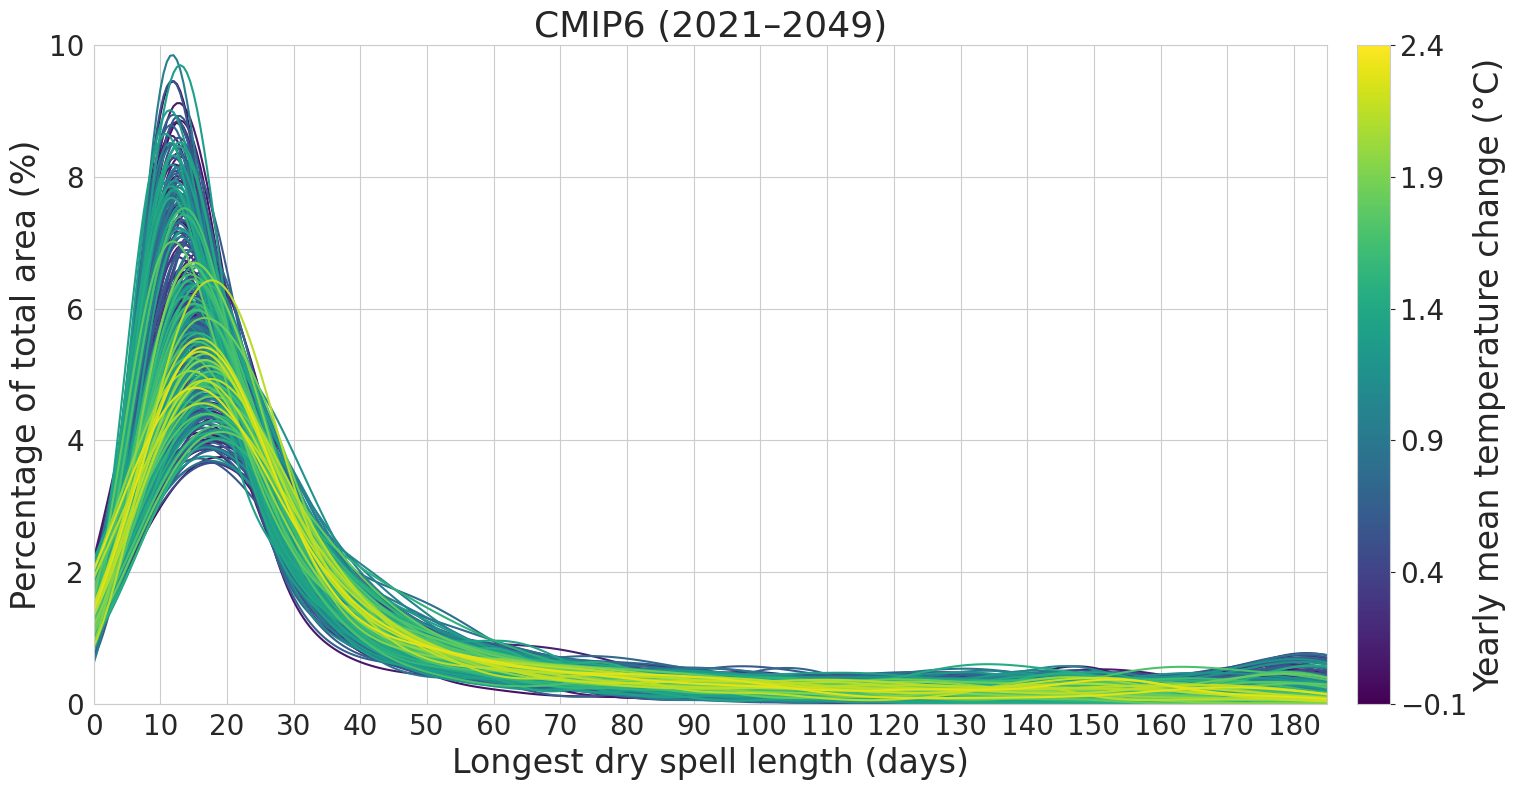

In [48]:
# ── plot: one line per model per year, coloured by the model's ensemble-mean land warming since REF_YEAR ──
dT_all = np.array([l['dT'] for l in lines])
vmin, vmax = CBAR_RANGE if CBAR_RANGE is not None else np.round(np.percentile(dT_all, [1, 99]), 1)
cmap = plt.get_cmap('viridis')
norm = plt.Normalize(vmin=vmin, vmax=vmax)

order = np.argsort(dT_all)                     # warmest lines drawn last (on top)
curves = np.array([lines[i]['curve'] for i in order]) * bin_width * 100   # density -> % per bin_width-day bin
segments = [np.column_stack([X_GRID, c]) for c in curves]

fig, ax = plt.subplots(figsize=(16, 8))
sns.set_style("whitegrid")
lc = LineCollection(segments, colors=cmap(norm(dT_all[order])), linewidths=LINE_WIDTH)
ax.add_collection(lc)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02, ticks=np.linspace(vmin, vmax, 6))
cbar.set_label('Yearly mean temperature change (°C)', fontsize=24)
cbar.ax.tick_params(labelsize=20)

ax.set_xticks(np.arange(xmin, xmax, 10))
ax.set_ylim(0, 10)
ax.set_xlim(xmin, xmax)
ax.set_xlabel('Longest dry spell length (days)', fontsize=24)
ax.set_ylabel('Percentage of total area (%)', fontsize=24)
ax.tick_params(axis='both', which='major', labelsize=20)
ax.set_title(f'CMIP6 ({YEARS[0]}–{YEARS[1]})', fontsize=26)
plt.tight_layout()
os.makedirs(os.path.dirname(OUT_FIG), exist_ok=True)
plt.savefig(OUT_FIG, format='pdf', bbox_inches='tight')
plt.show()

## Per-model panels

One panel per model with one line per member and year, coloured by the model's ensemble-mean land warming, using the same colour scale and axes as the figure above. Each panel shows the model's regression slope β₁ (days per °C, raw annual temperature) and R² from the table; R² is bold when p < 0.05.

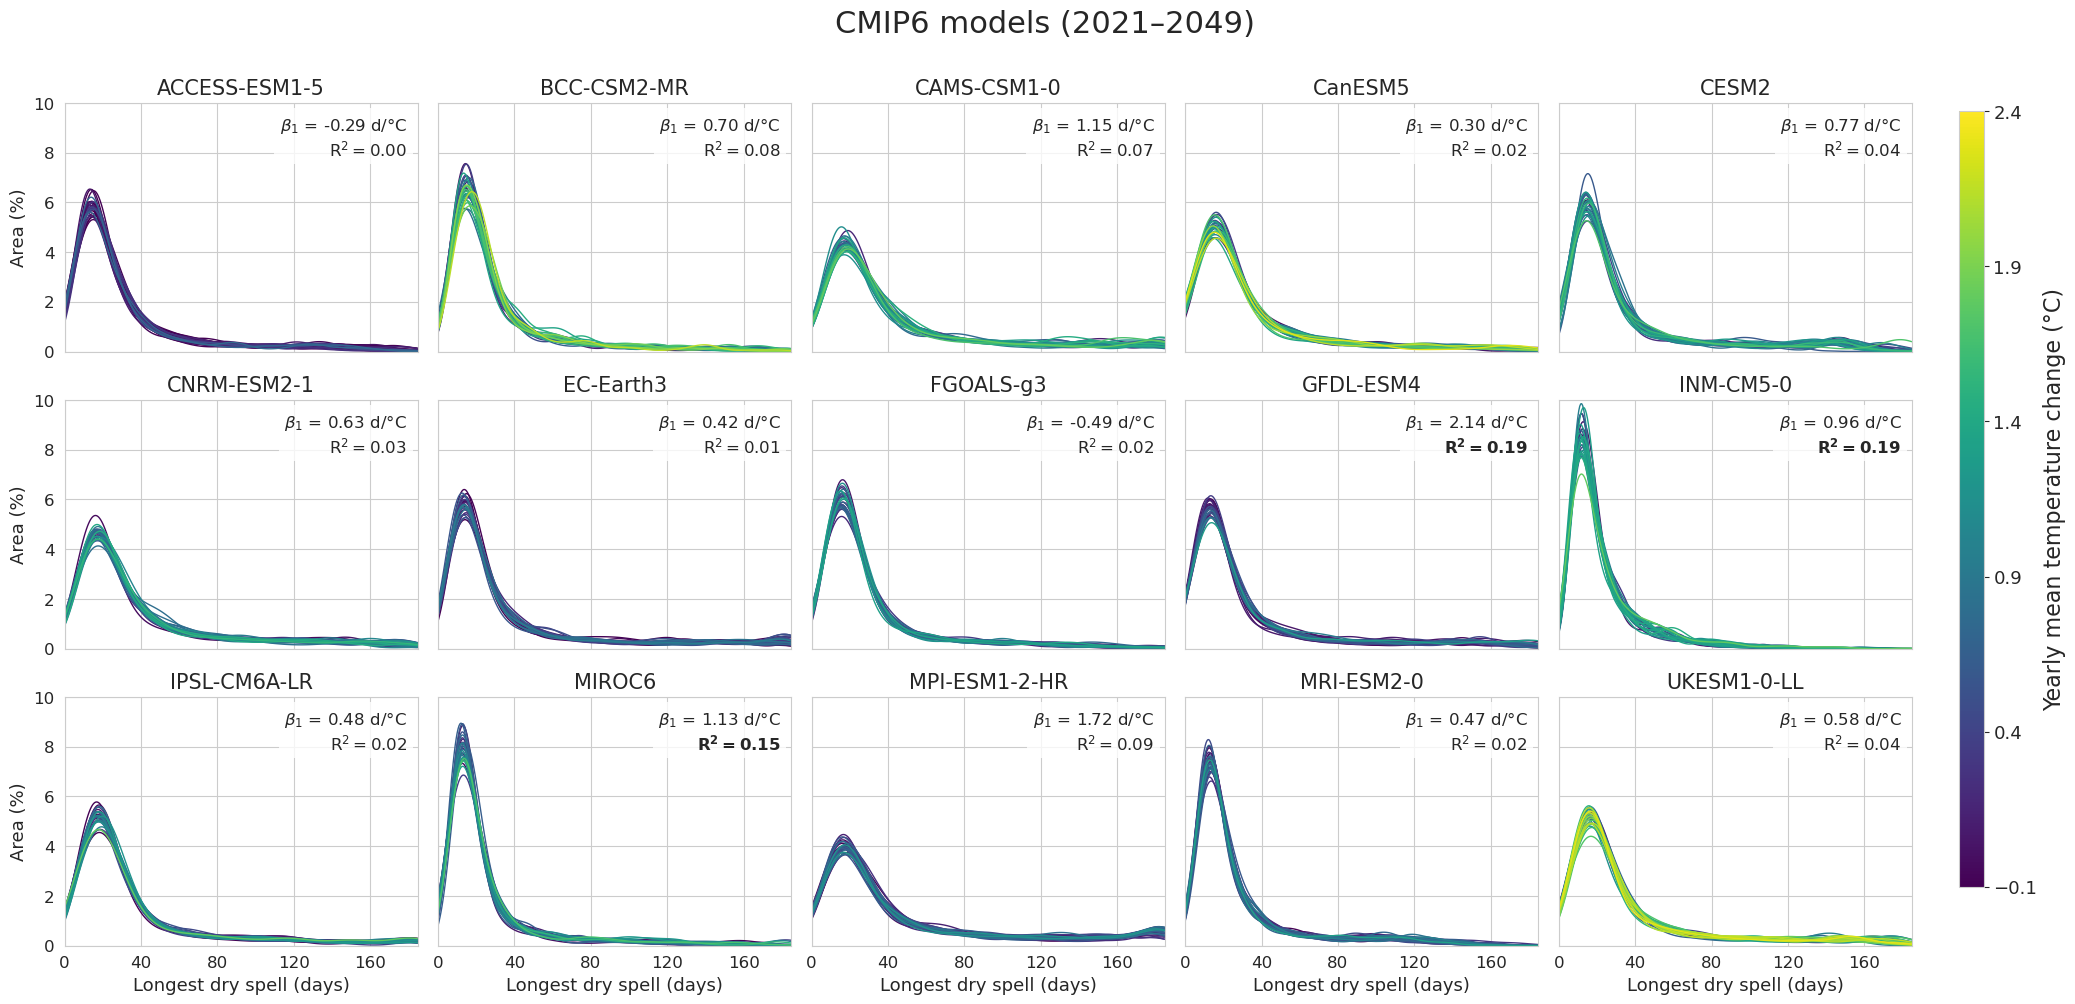

In [49]:
# ── one panel per model: one line per member and year, coloured by the model's ensemble-mean warming ──
models_plot = list(per_model)
n_rows = int(np.ceil(len(models_plot) / PANEL_COLS))
fig, axes = plt.subplots(n_rows, PANEL_COLS, figsize=(4.2 * PANEL_COLS, 3.4 * n_rows),
                         sharex=True, sharey=True, squeeze=False)
sns.set_style("whitegrid")

for ax, model in zip(axes.flat, models_plot):
    ml = sorted((l for l in member_lines if l['model'] == model), key=lambda l: l['dT'])   # warmest on top
    segs = [np.column_stack([X_GRID, l['curve'] * bin_width * 100]) for l in ml]
    ax.add_collection(LineCollection(segs, colors=cmap(norm([l['dT'] for l in ml])), linewidths=PANEL_LINE_WIDTH))
    r = regression.loc[model]
    n_mem = per_model[model]['n_members']
    ax.set_title(model if n_mem == 1 else f"{model} ({n_mem})", fontsize=15)   # (n) only if several members
    # beta1 = slope; R² in bold when the regression is significant (p < 0.05)
    r2_txt = (r'$\mathbf{R^2 = %.2f}$' if r['p_value'] < 0.05 else r'$\mathrm{R^2 = %.2f}$') % r['r_squared']
    ax.text(0.97, 0.95, rf"$\beta_1$ = {r['slope']:.2f} d/°C" + '\n' + r2_txt,
            transform=ax.transAxes, ha='right', va='top', fontsize=12,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(0, 10)
    ax.set_xticks(np.arange(xmin, xmax, 40))
    ax.tick_params(labelsize=12)

for ax in axes.flat[len(models_plot):]:          # hide unused panels
    ax.set_visible(False)
for ax in axes[-1, :]:
    ax.set_xlabel('Longest dry spell (days)', fontsize=13)
for ax in axes[:, 0]:
    ax.set_ylabel('Area (%)', fontsize=13)

fig.suptitle(f'CMIP6 models ({YEARS[0]}–{YEARS[1]})', fontsize=22)
fig.tight_layout(rect=(0, 0, 0.92, 0.97))
cax = fig.add_axes([0.935, 0.12, 0.012, 0.76])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax, ticks=np.linspace(norm.vmin, norm.vmax, 6))
cbar.set_label('Yearly mean temperature change (°C)', fontsize=16)
cbar.ax.tick_params(labelsize=13)

os.makedirs(os.path.dirname(OUT_FIG_PANELS), exist_ok=True)
plt.savefig(OUT_FIG_PANELS, format='pdf', bbox_inches='tight')
plt.show()